# 4. Explainability and fairness

Every decision returns SHAP-based reason codes. The audit measures approval gaps by gender and age band: it **measures** them, it does not certify fairness.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

METRICS = json.loads((ROOT / "reports" / "metrics.json").read_text())
SOURCE = METRICS["meta"]["data_source"]
display(Markdown(
    "> **Data source: real Home Credit data.**" if METRICS["meta"]["resume_safe"]
    else "> ⚠️ **SYNTHETIC DATA. Plumbing check only; do not read these numbers as findings.**"))

def load_application():
    """Real CSV if present and the reports came from it, otherwise the synthetic stand-in."""
    from src import synthetic
    path = ROOT / "data" / "application_train.csv"
    if METRICS["meta"]["resume_safe"] and path.exists():
        from src.pipeline import APP_COLUMNS
        return pd.read_csv(path, usecols=APP_COLUMNS)
    return synthetic.make_application_train(n=METRICS["meta"]["n_rows"], seed=METRICS["meta"]["seed"])


> **Data source: real Home Credit data.**

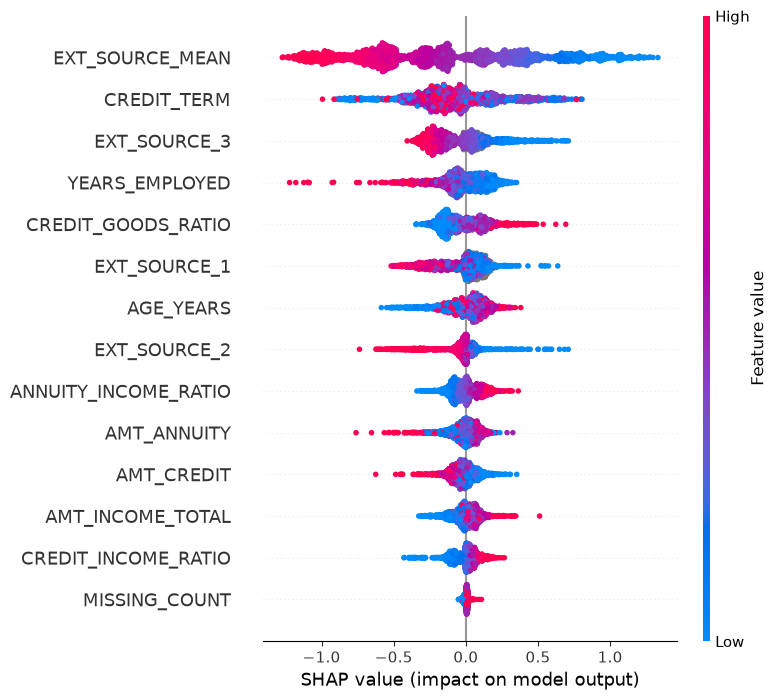

In [2]:
from src.engine import DecisionEngine
from src.features import FEATURE_COLUMNS, build_features
from src.model import load_bundle
import shap
bundle = load_bundle(ROOT / "models" / "model.joblib")
app = load_application()
X = build_features(app).sample(2000, random_state=0)
sv = bundle.shap_matrix(X)
plt.figure(); shap.summary_plot(sv, X[FEATURE_COLUMNS], show=False, max_display=14); plt.tight_layout(); plt.show()

## Reason codes for three kinds of applicant

In [3]:
engine = DecisionEngine(bundle)
cases = {"strong": dict(pan_hash="nb-1", age_years=38, annual_income=300000, loan_amount=300000, annuity=18000, years_employed=9, ext_source_2=0.78),
         "borderline": dict(pan_hash="nb-2", age_years=29, annual_income=150000, loan_amount=500000, annuity=30000, years_employed=2, ext_source_2=0.12),
         "weak": dict(pan_hash="nb-3", age_years=22, annual_income=80000, loan_amount=650000, annuity=38000, years_employed=0.3, ext_source_2=0.10)}
for name, req in cases.items():
    out = engine.decide(req)
    print(f"{name:11s} -> {out['decision']:8s} PD={out['pd']}  reasons: {[r['reason'] for r in out['reasons']]}")

strong      -> APPROVE  PD=0.021  reasons: ['Information not available: credit goods ratio', 'Information not available: ext source 3', 'Information not available: ext source 1']
borderline  -> DECLINE  PD=0.2929  reasons: ['Low external score', 'Information not available: credit goods ratio', 'Information not available: ext source 1']
weak        -> DECLINE  PD=0.4148  reasons: ['Low external score', 'High credit-to-income ratio', 'High repayment burden relative to income']


## Approval gaps (rules + ML policy, test set)

In [4]:
fa = METRICS["fairness"]
for attr in ["gender", "age_band"]:
    g = fa["rules_plus_ml"][attr]
    display(Markdown(f"**{attr}**: gap {g['gap_pts']} pts, 95% CI {g.get('gap_pts_ci95')}, adverse-impact ratio {g['adverse_impact_ratio']} "
                     f"(gap under rules only: {fa['current_rules_only'][attr]['gap_pts']} pts)"))
    display(pd.DataFrame(g["groups"]))

**gender**: gap 3.93 pts, 95% CI [3.24, 4.57], adverse-impact ratio 0.951 (gap under rules only: 8.64 pts)

,group,n,approval_rate,default_rate_among_approved,observed_default_rate_all,mean_pd,auc
0,F,40345,0.7596,0.0563,0.0696,0.0737,0.7618
1,M,21158,0.7989,0.0752,0.1020,0.0928,0.7544


**age_band**: gap 3.73 pts, 95% CI [2.79, 4.52], adverse-impact ratio 0.957 (gap under rules only: 8.5 pts)

,group,n,approval_rate,default_rate_among_approved,observed_default_rate_all,mean_pd,auc
0,21-30,10484,0.8298,0.0814,0.1150,0.1107,0.7413
1,31-45,24641,0.8671,0.0630,0.0877,0.0876,0.7690
2,46-60,20548,0.8509,0.0540,0.0645,0.0646,0.7455


Gender predicted from the model's own inputs: AUC 0.7364 (0.5 = no signal). Most informative: ['AMT_INCOME_TOTAL', 'YEARS_EMPLOYED', 'EXT_SOURCE_1']


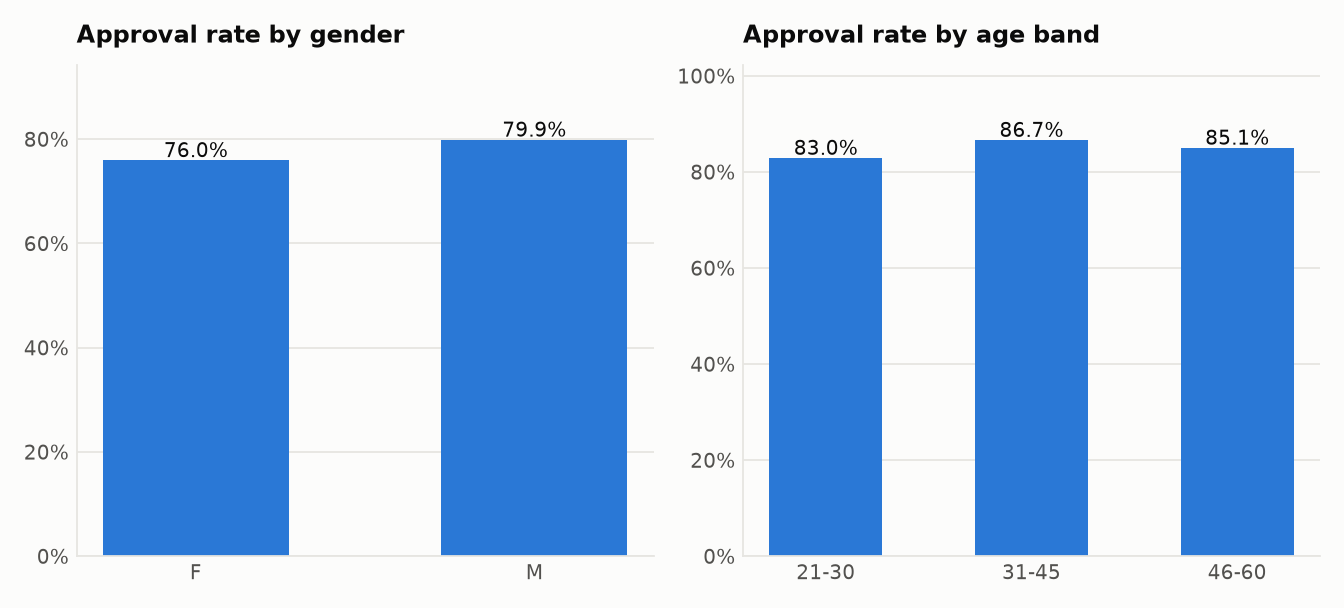

In [5]:
p = fa["proxy_test"]
print(f"Gender predicted from the model's own inputs: AUC {p['gender_from_features_auc']} (0.5 = no signal). Most informative: {p['top_predictive_features']}")
display(Image(filename=str(ROOT / "reports/figures/fairness.png"), width=620))

## How to read this

- A gap is not automatically unfairness: compare each group's **default rate among approved** and observed default rate. If a group is approved less *and* defaults more, the gap tracks risk; if not, investigate.
- **Age is a model input** and is also bounded by a hard rule (21-60), so an age-band gap is expected and needs a business and legal view.
- Next steps in practice: review features correlated with the attribute, test per-group thresholds only where legally permitted, monitor the gap over time.